In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras as layers

In [15]:
df = pd.read_csv("data\mnist_train.csv")
df.head(20)

C:\Users\aahan\AppData\Local\Temp\ipykernel_12720\115029169.py:1: DtypeWarning: Columns (0: label, 1: pixel1, 2: pixel2, 3: pixel3, 4: pixel4, 5: pixel5, 6: pixel6, 7: pixel7, 8: pixel8, 9: pixel9, 10: pixel10, 11: pixel11, 12: pixel12, 13: pixel13, 14: pixel14, 15: pixel15, 16: pixel16, 17: pixel17, 18: pixel18, 19: pixel19, 20: pixel20, 21: pixel21, 22: pixel22, 23: pixel23, 24: pixel24, 25: pixel25, 26: pixel26, 27: pixel27, 28: pixel28, 29: pixel29, 30: pixel30, 31: pixel31, 32: pixel32, 33: pixel33, 34: pixel34, 35: pixel35, 36: pixel36, 37: pixel37, 38: pixel38, 39: pixel39, 40: pixel40, 41: pixel41, 42: pixel42, 43: pixel43, 44: pixel44, 45: pixel45, 46: pixel46, 47: pixel47, 48: pixel48, 49: pixel49, 50: pixel50, 51: pixel51, 52: pixel52, 53: pixel53, 54: pixel54, 55: pixel55, 56: pixel56, 57: pixel57, 58: pixel58, 59: pixel59, 60: pixel60, 61: pixel61, 62: pixel62, 63: pixel63, 64: pixel64, 65: pixel65, 66: pixel66, 67: pixel67, 68: pixel68, 69: pixel69, 70: pixel70, 71: pixel

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,pixel11,pixel12,pixel13,pixel14,pixel15,pixel16,pixel17,pixel18,pixel19,pixel20,pixel21,pixel22,pixel23,pixel24,pixel25,pixel26,pixel27,pixel28,pixel29,pixel30,pixel31,pixel32,pixel33,pixel34,pixel35,pixel36,pixel37,pixel38,pixel39,...,pixel745,pixel746,pixel747,pixel748,pixel749,pixel750,pixel751,pixel752,pixel753,pixel754,pixel755,pixel756,pixel757,pixel758,pixel759,pixel760,pixel761,pixel762,pixel763,pixel764,pixel765,pixel766,pixel767,pixel768,pixel769,pixel770,pixel771,pixel772,pixel773,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,1x10,1x11,1x12,1x13,1x14,1x15,1x16,1x17,1x18,1x19,1x20,1x21,1x22,1x23,1x24,1x25,1x26,1x27,1x28,2x1,2x2,2x3,2x4,2x5,2x6,2x7,2x8,2x9,2x10,2x11,...,27x17,27x18,27x19,27x20,27x21,27x22,27x23,27x24,27x25,27x26,27x27,27x28,28x1,28x2,28x3,28x4,28x5,28x6,28x7,28x8,28x9,28x10,28x11,28x12,28x13,28x14,28x15,28x16,28x17,28x18,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
1,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,147,252,42,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [18]:
df = df.drop(0)

In [19]:
df.head(5)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,pixel11,pixel12,pixel13,pixel14,pixel15,pixel16,pixel17,pixel18,pixel19,pixel20,pixel21,pixel22,pixel23,pixel24,pixel25,pixel26,pixel27,pixel28,pixel29,pixel30,pixel31,pixel32,pixel33,pixel34,pixel35,pixel36,pixel37,pixel38,pixel39,...,pixel745,pixel746,pixel747,pixel748,pixel749,pixel750,pixel751,pixel752,pixel753,pixel754,pixel755,pixel756,pixel757,pixel758,pixel759,pixel760,pixel761,pixel762,pixel763,pixel764,pixel765,pixel766,pixel767,pixel768,pixel769,pixel770,pixel771,pixel772,pixel773,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
1,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,147,252,42,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [30]:
y_train = df["label"]
y_train = df["label"].astype("int32")
X_train = df.drop("label", axis=1)
X_train = X_train.apply(pd.to_numeric)
X_train = X_train / 255.0

In [31]:
print(X_train.dtypes.unique())
print(y_train.dtype)
print(X_train.info())

[dtype('float64')]
int32
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 1 to 60000
Columns: 784 entries, pixel1 to pixel784
dtypes: float64(784)
memory usage: 358.9 MB
None


In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input

In [41]:
model = Sequential([
    Dense(128,activation='relu',input_shape=(784,)),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')
])

c:\Users\aahan\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [42]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [43]:
model.fit(
    X_train,
    y_train,
    epochs = 10,
    validation_split = 0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9251 - loss: 0.2556 - val_accuracy: 0.9693 - val_loss: 0.1074
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9671 - loss: 0.1091 - val_accuracy: 0.9728 - val_loss: 0.0878
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9766 - loss: 0.0756 - val_accuracy: 0.9740 - val_loss: 0.0881
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9813 - loss: 0.0583 - val_accuracy: 0.9795 - val_loss: 0.0776
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9856 - loss: 0.0439 - val_accuracy: 0.9772 - val_loss: 0.0861
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9884 - loss: 0.0354 - val_accuracy: 0.9763 - val_loss: 0.0927
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9904 - loss: 0.0289 - val_accuracy: 0.9793 - val_loss: 0.0888
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9914 - loss: 0.0259 - 

In [49]:
testing_dataset = pd.read_csv('data\mnist_test.csv')
testing_dataset = testing_dataset.iloc[1:].reset_index(drop=True)
y_test = testing_dataset["label"].astype("int32")
x_test = testing_dataset.drop("label", axis=1).astype("float32") / 255.0
# y_train = y_train.to_numpy(dtype=np.int32)
y_train = y_train.astype(np.int32) 
y_test = np.asarray(y_test, dtype=np.int32)

X_train = np.asarray(X_train, dtype=np.float32)
x_test = np.asarray(x_test, dtype=np.float32)

C:\Users\aahan\AppData\Local\Temp\ipykernel_12720\3272654747.py:1: DtypeWarning: Columns (0: label, 1: pixel1, 2: pixel2, 3: pixel3, 4: pixel4, 5: pixel5, 6: pixel6, 7: pixel7, 8: pixel8, 9: pixel9, 10: pixel10, 11: pixel11, 12: pixel12, 13: pixel13, 14: pixel14, 15: pixel15, 16: pixel16, 17: pixel17, 18: pixel18, 19: pixel19, 20: pixel20, 21: pixel21, 22: pixel22, 23: pixel23, 24: pixel24, 25: pixel25, 26: pixel26, 27: pixel27, 28: pixel28, 29: pixel29, 30: pixel30, 31: pixel31, 32: pixel32, 33: pixel33, 34: pixel34, 35: pixel35, 36: pixel36, 37: pixel37, 38: pixel38, 39: pixel39, 40: pixel40, 41: pixel41, 42: pixel42, 43: pixel43, 44: pixel44, 45: pixel45, 46: pixel46, 47: pixel47, 48: pixel48, 49: pixel49, 50: pixel50, 51: pixel51, 52: pixel52, 53: pixel53, 54: pixel54, 55: pixel55, 56: pixel56, 57: pixel57, 58: pixel58, 59: pixel59, 60: pixel60, 61: pixel61, 62: pixel62, 63: pixel63, 64: pixel64, 65: pixel65, 66: pixel66, 67: pixel67, 68: pixel68, 69: pixel69, 70: pixel70, 71: pixe

In [50]:
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)
accuracy = np.mean(predicted_labels == y_test)
print(f"Test Accuracy: {accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step
Test Accuracy: 0.9751


Number wrong: 249


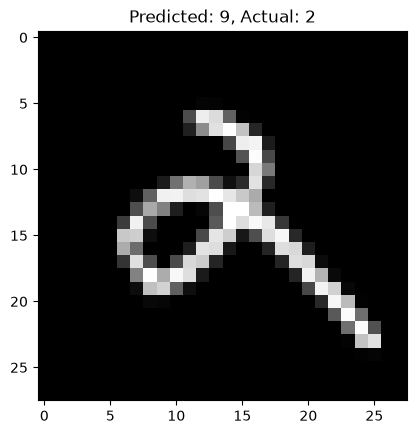

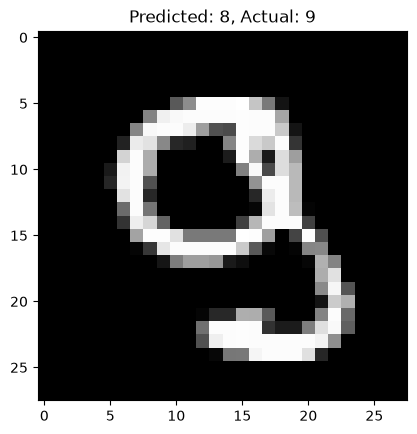

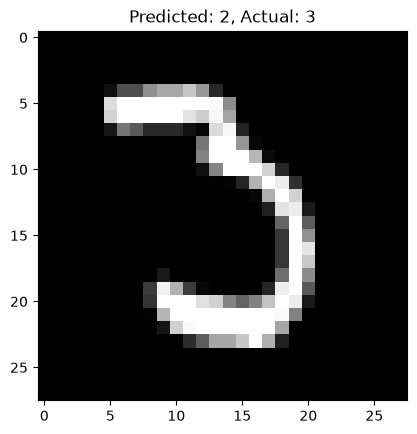

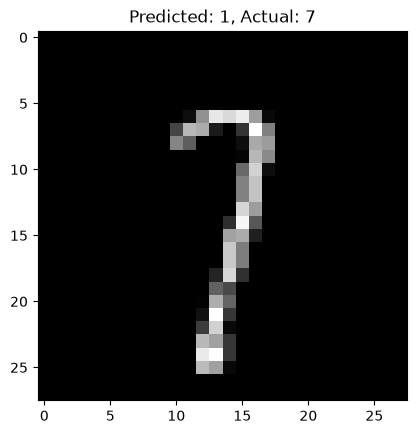

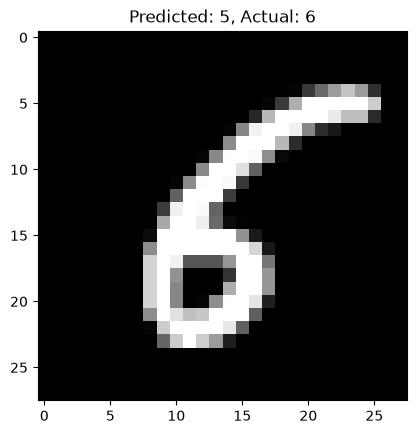

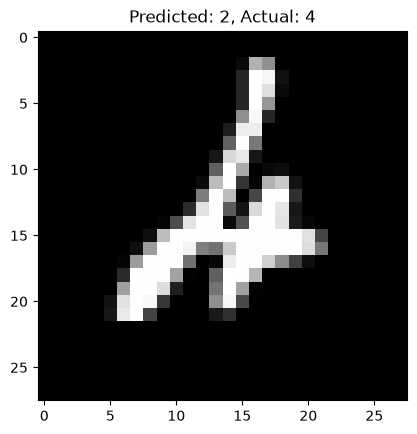

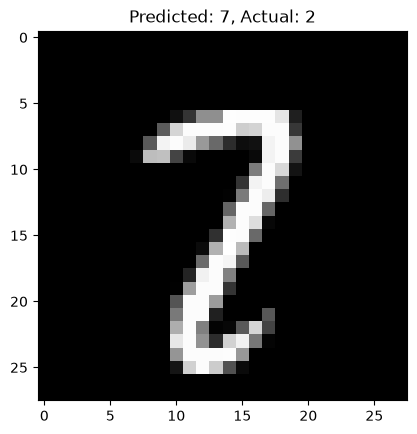

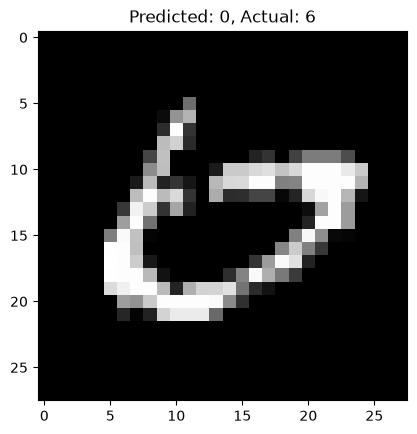

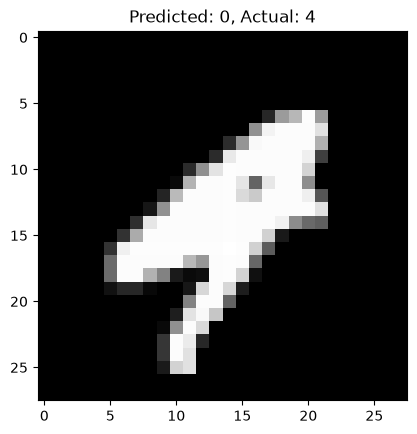

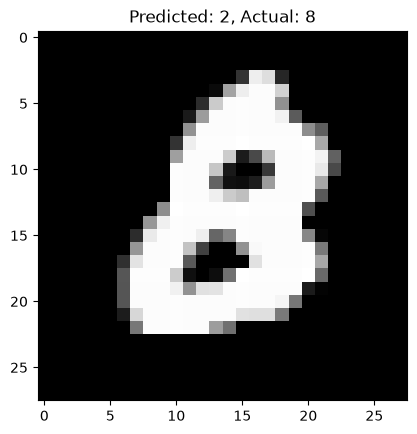

In [51]:
wrong = np.where(predicted_labels != y_test)[0]

print("Number wrong:", len(wrong))
import matplotlib.pyplot as plt

for i in range(10):
    idx = wrong[i]
    plt.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    plt.title(
        f"Predicted: {predicted_labels[idx]}, Actual: {y_test[idx]}"
    )
    plt.show()